In [19]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Permittivity_study\fit_interband_permittivity')
from fit_interband_func import *
import fit_interband_func
importlib.reload(fit_interband_func)
from fit_interband_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [20]:
Ag_band_info = {}

## From the mathematica code used for Stoll 2014

Source = 'Rosei 1974' #As it is named in the mathematica code
Source = 'Stoll 2014 fitted'


Ag_info = {}



Ag_info['Rosei 1974'] = {}
# Masses in electron mass unit    
Ag_info['Rosei 1974']['m_d_perp'] = 2.075
Ag_info['Rosei 1974']['m_d_par'] = 2.580
Ag_info['Rosei 1974']['m_p_perp'] = 0.320
Ag_info['Rosei 1974']['m_p_par'] = 0.172  
Ag_info['Rosei 1974']['m_s_perp'] = 5.160
Ag_info['Rosei 1974']['m_s_par'] = 0.128
#Optical gaps in eV from Rosei
Ag_info['Rosei 1974']['wf'] = 310e-3 #in eV
Ag_info['Rosei 1974']['wo'] = 3680e-3 #in eV
Ag_info['Rosei 1974']['wg'] = 3850e-3 #in eV
# Fermi Energy from Ascroft solid state physics
Ag_info['Rosei 1974']['Ef'] = 5.490 #in eV
#Drude parameters
Ag_info['Rosei 1974']['wp'] = 8.98 #in eV
Ag_info['Rosei 1974']['gamma0'] = 0.02 #in eV




Ag_info['Stoll 2014 fitted'] = {}
# Masses in electron mass unit    
Ag_info['Stoll 2014 fitted']['m_d_perp'] = 2.075
Ag_info['Stoll 2014 fitted']['m_d_par'] = 2.580
Ag_info['Stoll 2014 fitted']['m_p_perp'] = 0.320
Ag_info['Stoll 2014 fitted']['m_p_par'] = 0.172 
Ag_info['Stoll 2014 fitted']['m_s_perp'] = 5.160
Ag_info['Stoll 2014 fitted']['m_s_par'] = 0.128
#Optical gaps in eV from Rosei
Ag_info['Stoll 2014 fitted']['wf'] = 310e-3 #in eV
Ag_info['Stoll 2014 fitted']['wo'] = 3632e-3 #in eV
Ag_info['Stoll 2014 fitted']['wg'] = 3684e-3 #in eV
# Fermi Energy from Ascroft solid state physics
Ag_info['Stoll 2014 fitted']['Ef'] = 5.490 #in eV
#Drude parameters
Ag_info['Stoll 2014 fitted']['wp'] = 8.98 #in eV
Ag_info['Stoll 2014 fitted']['gamma0'] = 0.02 #in eV

Ag_band_info = Ag_info['Stoll 2014 fitted']


Ef = Ag_band_info['Ef'] #in eV
Emin = Ef - 5

m_p_perp = Ag_band_info['m_p_perp']
m_p_par = Ag_band_info['m_p_par']
m_s_perp = Ag_band_info['m_s_perp']
m_s_par = Ag_band_info['m_s_par']

#gaps in eV
wf = Ag_band_info['wf'] 
wg = Ag_band_info['wg']




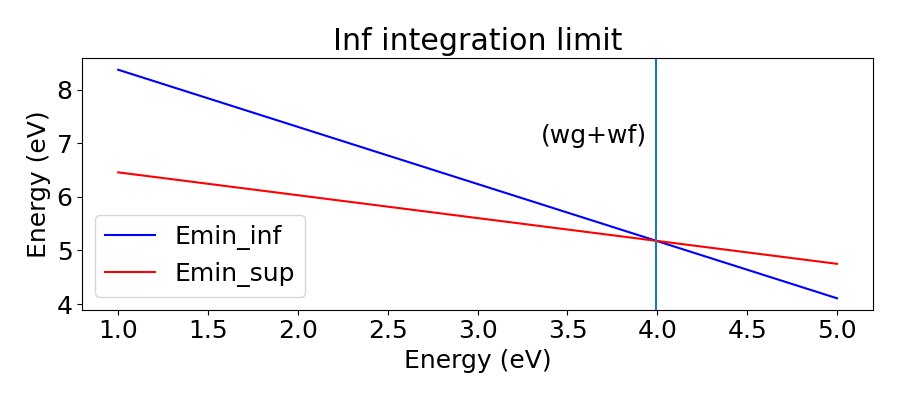

In [21]:
W = np.linspace(1, 5, 1000)

Emin_inf = (Ef - wf + (m_s_perp/(m_s_perp - m_p_perp))*(wg + wf- W))
Emin_sup = (Ef - wf + (m_s_par/(m_s_par + m_p_par))*(wg + wf- W))


fig, ax =plt.subplots(figsize=(9,4))
ax.plot(W, Emin_inf, color='blue', label='Emin_inf')
ax.plot(W, Emin_sup, color='red', label='Emin_sup')
ax.axvline((wg+wf))
ax.set_xlabel('Energy (eV)')
ax.set_ylabel('Energy (eV)')
ax.text(3.35, 7, '(wg+wf)')
ax.set_title('Inf integration limit')
ax.legend()


plt.tight_layout()

C:\Users\nberr\AppData\Local\Temp\ipykernel_16284\3207470826.py:7: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



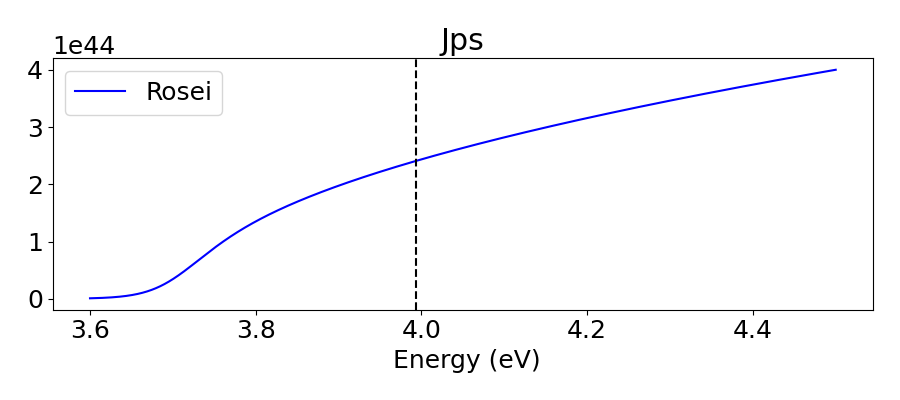

In [22]:
E = np.linspace(3.6, 4.5, 10000) #in eV
prefactor = 8*np.pi**2 * sc.constants.hbar**2 / (sc.constants.epsilon_0*sc.constants.m_e**2)


Jps = Jps_Ag(E, **Ag_info['Stoll 2014 fitted'])

fig, ax =plt.subplots(figsize=(9,4))

ax.plot(E, Jps, color='blue', label = 'Rosei')
#ax.plot(E, Jps2, color='green', label = 'Stoll 2014 fitted')
ax.axvline((wg + wf), color='black', linestyle='--')
ax.set_xlabel(' Energy (eV)')
ax.set_title('Jps')
ax.legend()
plt.tight_layout()